# Módulo 2: Segmentación y Morfología Matemática de la Pupila

**Objetivo:** Aislar de forma robusta la estructura de la pupila en el frame de trabajo y extender el algoritmo a través del tiempo.

**Datos:** Se utiliza el mismo frame y la misma ROI que en el Módulo 1. El video se define en `config.py` mediante la variable `VIDEO_PATH`.

In [13]:
# Para que encuentre config.py, que está otra carpeta
import sys
sys.path.append("..")

import cv2
import numpy as np
import matplotlib.pyplot as plt
from config import VIDEO_PATH

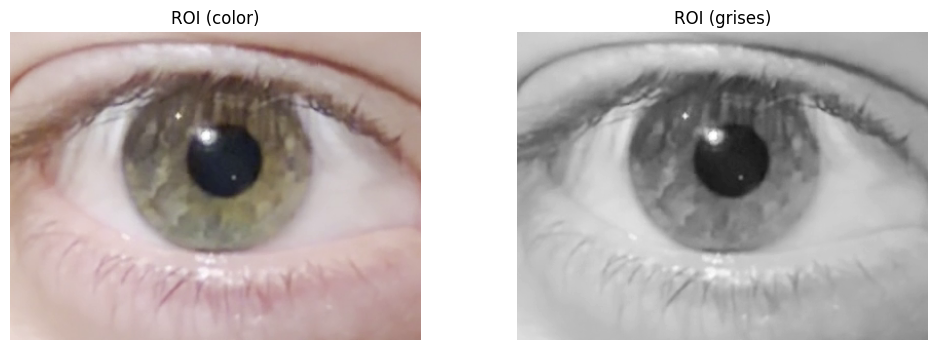

In [14]:
# Mismo frame y ROI que en el Módulo 1
FRAME_IDX = 778
x, y, w, h = 300, 950, 400, 300

# Leemos el frame elegido del video
cap = cv2.VideoCapture(str(VIDEO_PATH))
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_IDX)
ok, frame = cap.read()
cap.release()

# Pasamos de BGR (formato de OpenCV) a RGB y recortamos la ROI
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
roi = frame_rgb[y:y+h, x:x+w]

# Versión en escala de grises: es la que usan la mayoría de los métodos
roi_gris = cv2.cvtColor(roi, cv2.COLOR_RGB2GRAY)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(roi)
axes[0].set_title("ROI (color)")
axes[1].imshow(roi_gris, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("ROI (grises)")
for ax in axes:
    ax.axis("off")
plt.show()

## 1. Algoritmos de Segmentación

Se aplican y comparan distintos métodos para aislar la pupila del iris y la esclerótica.

### Umbralización automática de Otsu

El método de Otsu determina automáticamente un umbral global $T$ a partir del histograma de la imagen. Prueba todos los umbrales posibles y elige el que maximiza la varianza entre las dos clases resultantes (píxeles oscuros y claros), es decir, el que las separa mejor.

Como la pupila es la región más oscura del ojo, se asignan a la máscara los píxeles con intensidad menor o igual al umbral.

Umbral de Otsu: T = 141


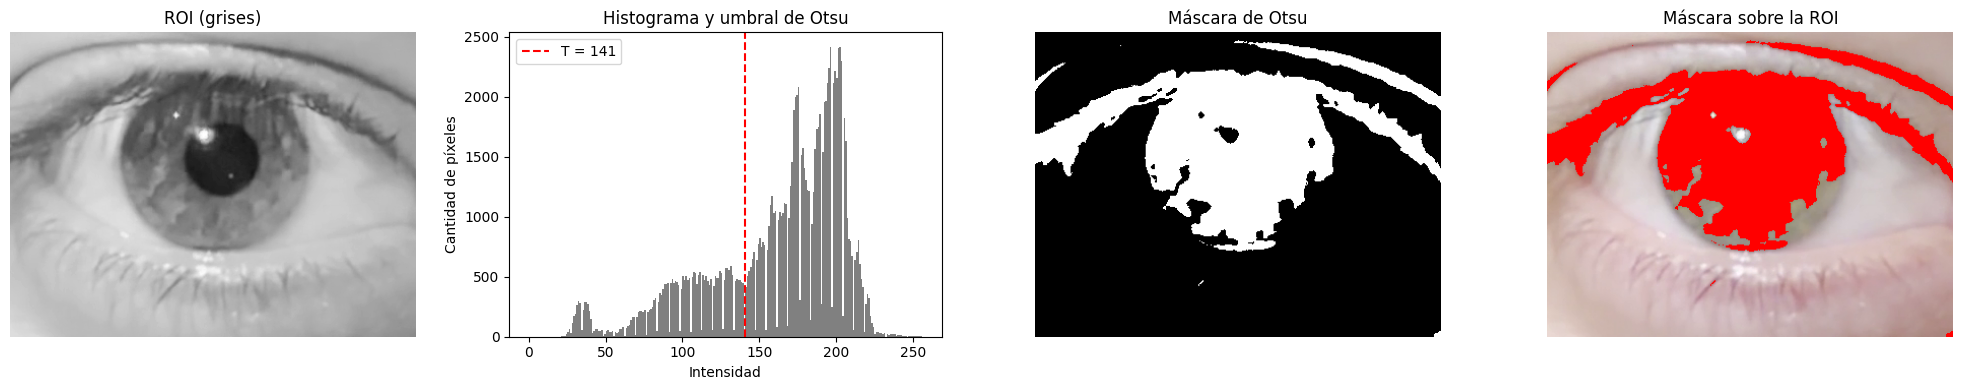

In [15]:

# Umbralización de Otsu
T_otsu, mascara_otsu = cv2.threshold(
    roi_gris, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)
# T_otsu: el umbral que eligió Otsu
# mascara_otsu: la imagen binaria resultante
# THRESH_BINARY_INV: los píxeles OSCUROS (≤ T) quedan en 255 así la pupila aparece en blanco en la máscara

print(f"Umbral de Otsu: T = {T_otsu:.0f}")

# Visualización
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

# 1) ROI en grises, como referencia
axes[0].imshow(roi_gris, cmap="gray", vmin=0, vmax=255)
axes[0].set_title("ROI (grises)")
axes[0].axis("off")

# 2) Histograma con el umbral marcado
axes[1].hist(roi_gris.ravel(), bins=256, range=(0, 256), color="gray")
axes[1].axvline(T_otsu, color="red", linestyle="--", label=f"T = {T_otsu:.0f}")
axes[1].set_title("Histograma y umbral de Otsu")
axes[1].set_xlabel("Intensidad")
axes[1].set_ylabel("Cantidad de píxeles")
axes[1].legend()

# 3) Máscara binaria: blanco = píxeles por debajo del umbral
axes[2].imshow(mascara_otsu, cmap="gray")
axes[2].set_title("Máscara de Otsu")
axes[2].axis("off")

# 4) Máscara superpuesta en rojo sobre la ROI, para ver qué agarró
superpuesta = roi.copy()
superpuesta[mascara_otsu == 255] = [255, 0, 0]
axes[3].imshow(superpuesta)
axes[3].set_title("Máscara sobre la ROI")
axes[3].axis("off")

plt.tight_layout()
plt.show()

El método de Otsu determinó un umbral global de $T = 141$. En el histograma se distinguen tres zonas: un pico pequeño en intensidades bajas (aproximadamente entre 25 y 45), que corresponde a la pupila; una región amplia de intensidades intermedias (entre 60 y 140), asociada al iris, las pestañas y las sombras de los párpados; y un pico grande en intensidades altas (entre 160 y 220), correspondiente a la esclerótica y la piel.

Otsu separa la imagen en solo dos clases, y el umbral elegido cae entre la región intermedia y la clara. Por lo tanto, la máscara obtenida no aísla la pupila sino que incluye la pupila, gran parte del iris, el pliegue del párpado superior y las pestañas. Además, el iris no queda segmentado de forma completa sino con huecos irregulares, porque su textura tiene intensidades a ambos lados del umbral.

Esto se debe a que la pupila ocupa una fracción muy pequeña de la ROI. Como Otsu maximiza la varianza entre dos clases, el umbral queda dominado por la separación entre las regiones que tienen más píxeles (estructuras oscuras e intermedias frente a la esclerótica y la piel), y no por la separación entre pupila e iris. Observando el histograma, un umbral cercano a 50 separaría mucho mejor el pico de la pupila del resto.

En conclusión, la umbralización global de Otsu aplicada directamente sobre la ROI no es suficiente para segmentar la pupila. Para mejorar el resultado sería necesario reducir la ROI a la región del iris, aplicar Otsu sobre la clase oscura obtenida, o utilizar métodos que permitan más de dos clases, como K-Means.

### Agrupamiento K-Means

K-Means agrupa los píxeles en *K* clases según su similitud. Cada píxel se representa en el espacio de color Lab, donde L corresponde a la intensidad y a, b a la croma. El algoritmo asigna cada píxel al centro más cercano y recalcula los centros de forma iterativa hasta converger.

Se evalúan valores de K entre 2 y 5. En cada caso, se toma como pupila la clase con menor intensidad media (menor L).

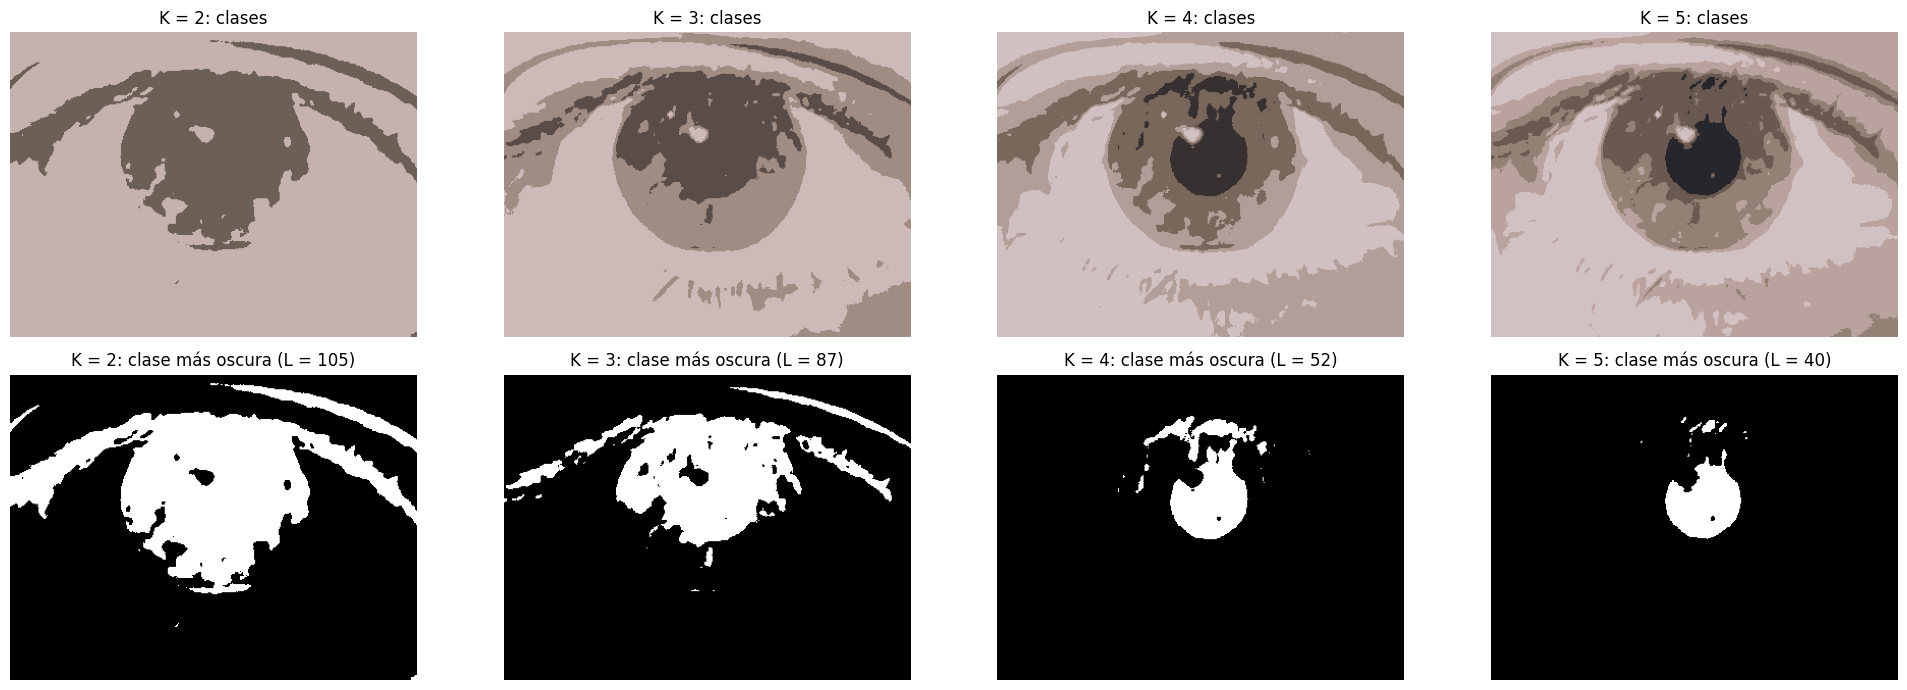

In [16]:
# Preparación de los datos
# Pasamos la ROI de RGB a Lab:
roi_lab = cv2.cvtColor(roi, cv2.COLOR_RGB2LAB)

# K-Means necesita una lista de "puntos": una fila por píxel y una columna por característica (L, a, b). 
# Pasamos de alto × ancho × 3   a (alto·ancho) × 3, y a float32
datos = roi_lab.reshape(-1, 3).astype(np.float32)

# Criterio de parada: frena cuando hizo 100 iteraciones o cuando los centros se mueven menos de 0.2
criterio = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

valores_K = [2, 3, 4, 5]
mascaras_kmeans = {}   # guardamos la máscara de pupila de cada K

fig, axes = plt.subplots(2, len(valores_K), figsize=(20, 7))

for j, K in enumerate(valores_K):
    _, etiquetas, centros = cv2.kmeans(
        datos, K, None, criterio, 10, cv2.KMEANS_PP_CENTERS
    )
    # etiquetas: a qué clase (0 a K-1) pertenece cada píxel
    # centros: el valor (L, a, b) promedio de cada clase

    # Volvemos a darle forma de imagen: alto × ancho
    etiquetas = etiquetas.reshape(roi_gris.shape)

    # Elegimos la clase de la pupila: la de menor L (más oscura)
    clase_pupila = np.argmin(centros[:, 0])
    mascara = (etiquetas == clase_pupila).astype(np.uint8) * 255
    mascaras_kmeans[K] = mascara

    # Visualización: pasamos los centros de Lab a RGB para mostrarlos
    centros_rgb = cv2.cvtColor(
        centros.astype(np.uint8).reshape(1, K, 3), cv2.COLOR_LAB2RGB
    ).reshape(K, 3)
    axes[0, j].imshow(centros_rgb[etiquetas])
    axes[0, j].set_title(f"K = {K}: clases")

    # Fila 1: máscara de la clase más oscura (candidata a pupila)
    axes[1, j].imshow(mascara, cmap="gray")
    axes[1, j].set_title(f"K = {K}: clase más oscura (L = {centros[clase_pupila, 0]:.0f})")

for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

Con **K = 2**, K-Means divide la imagen en una clase oscura y una clara, con un resultado muy similar al de Otsu: la clase más oscura (L = 105) incluye la pupila, gran parte del iris, el pliegue del párpado superior y las pestañas.

Con **K = 3**, aparece una clase intermedia que separa parte del iris y de la piel en sombra, pero la clase más oscura (L = 87) sigue incluyendo la pupila junto con el iris y las pestañas.

A partir de **K = 4**, la clase más oscura (L = 52) se reduce principalmente a la pupila, que ya se distingue como una región circular. Sin embargo, todavía incluye fragmentos de la parte superior del iris, sombreada por el párpado, y algunas pestañas.

Con **K = 5**, la clase más oscura (L = 40) es la que mejor aísla la pupila. Quedan solo pequeños fragmentos del iris adheridos a su borde superior y algunos píxeles aislados de las pestañas, que podrían eliminarse mediante operaciones morfológicas. Además, dentro de la región pupilar se observa un pequeño hueco, causado por un reflejo corneal secundario, y el borde superior izquierdo de la pupila presenta una irregularidad en la zona del reflejo principal. Estos defectos, junto con los fragmentos del iris adheridos, son los que se buscan corregir en la sección de morfología matemática (por ejemplo, rellenando huecos mediante un cierre y eliminando fragmentos con una apertura).

A diferencia de Otsu, que está limitado a dos clases, K-Means permite separar la imagen en tantas regiones como estructuras tenga el ojo (pupila, iris, esclerótica, piel y sombras). Al aumentar K, la clase más oscura se vuelve más específica de la pupila. 

### Contornos activos (Snakes)

Un contorno activo es una curva que se deforma iterativamente para minimizar una energía compuesta por dos términos:
- Fuerzas internas: controlan la forma de la curva. La elasticidad ($\alpha$) la hace contraerse y mantener los puntos equiespaciados; la rigidez ($\beta$) la mantiene suave y evita curvas bruscas.
- Fuerzas externas: atraen la curva hacia los bordes de la imagen ($w_{edge}$).

Como contorno inicial se utiliza un círculo centrado en la pupila, obtenido a partir de la máscara de K-Means (K = 5), con un radio mayor al de la pupila para que la rodee por completo. El contorno se contrae hasta detenerse en la frontera entre la pupila y el iris.

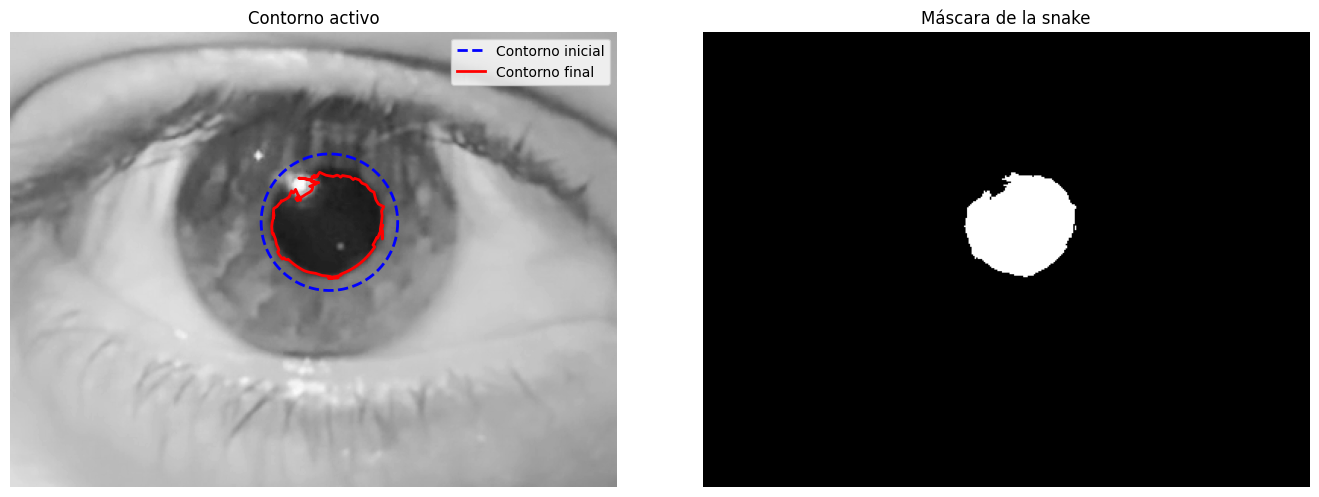

In [17]:
from skimage.segmentation import active_contour
from skimage.filters import gaussian
from skimage.draw import polygon

# 1) Contorno inicial: círculo elegido a mano alrededor de la pupila
x_c, y_c = 210, 125 # centro de la pupila
radio_inicial = 45 # un poco mayor que la pupila (radio 34 px)

angulos = np.linspace(0, 2 * np.pi, 200)
contorno_inicial = np.array([
    y_c + radio_inicial * np.sin(angulos), 
    x_c + radio_inicial * np.cos(angulos)  
]).T

# 2) Ajuste del contorno activo
# Suavizado fuerte: borra la textura del iris y atenúa el reflejo para que el contorno solo "vea" el borde pupila–iris
roi_suave = gaussian(roi_gris, sigma=5, preserve_range=True)

contorno_final = active_contour(
    roi_suave,
    contorno_inicial,
    alpha=0.015, # elasticidad: tendencia a contraerse
    beta=30, # rigidez: mantiene el contorno redondeado
    w_line=0, # no se atrae a zonas claras ni oscuras en sí
    w_edge=1, # se atrae a los bordes
    gamma=0.001, # tamaño del paso en cada iteración
    max_num_iter=2500
)

# 3) Máscara binaria: rellenamos el interior del contorno final
mascara_snake = np.zeros_like(roi_gris)
filas, cols = polygon(contorno_final[:, 0], contorno_final[:, 1], roi_gris.shape)
mascara_snake[filas, cols] = 255

# 4) Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(roi_gris, cmap="gray", vmin=0, vmax=255)
axes[0].plot(contorno_inicial[:, 1], contorno_inicial[:, 0], "--b", lw=2, label="Contorno inicial")
axes[0].plot(contorno_final[:, 1], contorno_final[:, 0], "-r", lw=2, label="Contorno final")
axes[0].legend(loc="upper right")
axes[0].set_title("Contorno activo")

axes[1].imshow(mascara_snake, cmap="gray")
axes[1].set_title("Máscara de la snake")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Se inicializó el contorno como un círculo de radio 45 px centrado en la pupila, y se ajustó con $\alpha = 0.015$, $\beta = 30$ y $w_{edge} = 1$ sobre la ROI suavizada con un filtro Gaussiano ($\sigma = 5$).

El contorno final se ajusta correctamente a la frontera entre la pupila y el iris en casi todo su perímetro, y la máscara resultante es compacta y aproximadamente circular. A diferencia de Otsu y K-Means, no incluye fragmentos del iris ni de las pestañas, ya que el contorno es una única curva cerrada que solo puede encerrar una región. La única imperfección es una pequeña muesca en el borde superior izquierdo, causada por el reflejo corneal, que genera un borde intenso y atrae al contorno.

Para lograr este resultado fue necesario ajustar los parámetros. Con poco suavizado, el contorno se detenía en la textura del iris, cuyas manchas generan bordes que compiten con el de la pupila. Con una elasticidad alta, el contorno atravesaba el borde superior de la pupila, que tiene bajo contraste porque el iris está oscurecido por la sombra del párpado. Un suavizado fuerte ($\sigma = 5$) elimina la textura del iris y deja como borde dominante la frontera pupila–iris, mientras que una rigidez alta ($\beta = 30$) mantiene el contorno redondeado.

Se observó además que el método es muy sensible al contorno inicial: desplazar el centro unos pocos píxeles o agrandar el radio inicial puede hacer que el contorno converja a un resultado incorrecto. En cambio, pequeñas variaciones de $\alpha$ o $\sigma$ afectan poco al resultado. Esta dependencia de la inicialización es la principal desventaja de los contornos activos frente a Otsu o K-Means. 

### Watershed (Cuenca Hidrográfica)

El algoritmo de watershed interpreta la imagen como un relieve topográfico. Se utiliza la magnitud del gradiente, de modo que los bordes corresponden a "crestas" y las regiones uniformes a "valles". El relieve se inunda progresivamente desde sus mínimos, y las líneas donde se encuentran las aguas de distintas cuencas definen los límites entre regiones.

Aplicado directamente, el método genera una cuenca por cada mínimo local del gradiente, lo que produce sobresegmentación. Para evitarlo, se utilizan marcadores así la inundación parte solo desde regiones elegidas previamente. Se definen tres marcadores: pupila, fondo (iris claro, esclerótica y piel) y reflejos corneales.

Watershed sin marcadores: 4507 regiones


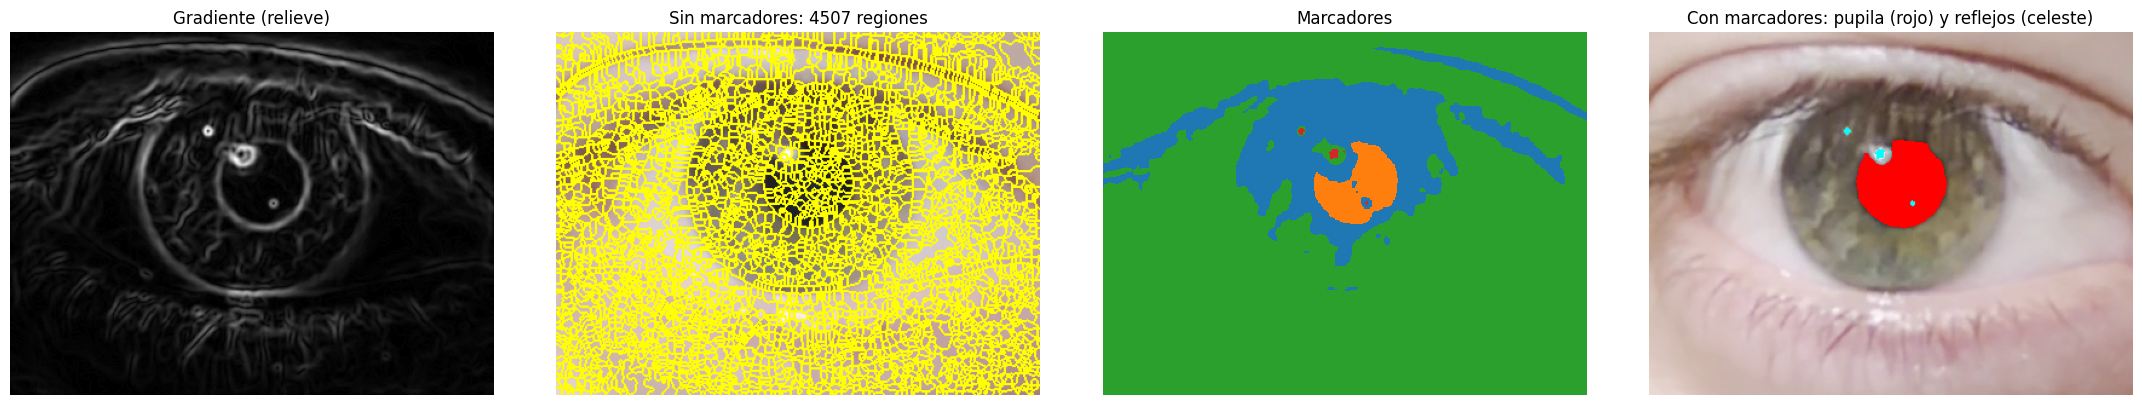

In [ ]:
from skimage.segmentation import watershed, mark_boundaries
from skimage.filters import sobel

# 1) El relieve: magnitud del gradiente
# Suavizamos un poco antes, para que el ruido no genere bordes falsos
roi_suave = cv2.GaussianBlur(roi_gris, (5, 5), 1.5)

# Sobel calcula la magnitud del gradiente en cada píxel. Los valores altos son bordes ("montañas")
gradiente = sobel(roi_suave.astype(float))

# 2) Watershed SIN marcadores: inunda desde todos los mínimos locales del gradiente y cada mínimo genera su propia región
etiquetas_sin_marc = watershed(gradiente)
print(f"Watershed sin marcadores: {etiquetas_sin_marc.max()} regiones")

# 3) Marcadores: desde dónde arranca la inundación
marcadores = np.zeros(roi_gris.shape, dtype=np.int32)

# Marcador 1: pupila = píxeles muy oscuros
marcadores[roi_suave < 40] = 1

# Marcador 2: fondo = píxeles claros 
marcadores[roi_suave > 120] = 2

# Marcador 3: reflejos = píxeles mucho más brillantes que su entorno aplicando un filtro de mediana
diferencia = roi_gris.astype(int) - cv2.medianBlur(roi_gris, 15).astype(int)
marcadores[diferencia > 60] = 3

# 4) Watershed CON marcadores
etiquetas_ws = watershed(gradiente, marcadores)

# Máscaras binarias de cada región que nos interesa
mascara_watershed = (etiquetas_ws == 1).astype(np.uint8) * 255 # pupila
mascara_reflejos = (etiquetas_ws == 3).astype(np.uint8) * 255 # reflejos


# 5) Visualización
fig, axes = plt.subplots(1, 4, figsize=(22, 4))

axes[0].imshow(gradiente, cmap="gray")
axes[0].set_title("Gradiente (relieve)")

# mark_boundaries dibuja en amarillo los límites entre regiones
axes[1].imshow(mark_boundaries(roi, etiquetas_sin_marc))
axes[1].set_title(f"Sin marcadores: {etiquetas_sin_marc.max()} regiones")

# Colores: azul = sin marcar, naranja = pupila, verde = fondo, rojo = reflejos
axes[2].imshow(marcadores, cmap="tab10", vmin=0, vmax=9, interpolation="nearest")
axes[2].set_title("Marcadores")

# Resultado superpuesto: pupila en rojo, reflejos en celeste
superpuesta = roi.copy()
superpuesta[etiquetas_ws == 1] = [255, 0, 0]
superpuesta[etiquetas_ws == 3] = [0, 255, 255]
axes[3].imshow(superpuesta)
axes[3].set_title("Con marcadores: pupila (rojo) y reflejos (celeste)")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

El gradiente de Sobel funciona como relieve topográfico donde los bordes de la pupila, del iris, de los párpados y de los reflejos aparecen como crestas brillantes, mientras que el interior de la pupila y las zonas uniformes de la piel quedan como valles oscuros.

Sin marcadores, el algoritmo genera 4507 regiones. Cada mínimo local del gradiente da origen a su propia cuenca, por lo que la textura del iris, las pestañas y las pequeñas variaciones de la piel fragmentan la imagen. Esta sobresegmentación es la principal desventaja del watershed aplicado directamente sobre imágenes no homogéneas o con ruido.

Con marcadores, la inundación parte solo desde tres regiones definidas previamente: la pupila (píxeles con intensidad menor a 40), el fondo (intensidad mayor a 120) y los reflejos (píxeles que superan en más de 60 niveles a la mediana entre sus vecinos). Los píxeles intermedios, que no pertenecen a ningún marcador, se asignan a la cuenca que los alcanza primero durante la inundación, y el límite queda ubicado sobre la cresta del gradiente.

El resultado separa correctamente la pupila de los reflejos corneales. La pupila se obtiene como una región compacta y circular, sin fragmentos del iris ni de las pestañas, a diferencia de Otsu y K-Means. Se identifican además tres reflejos: el principal, en el borde superior izquierdo de la pupila; uno secundario, dentro de la pupila; y uno pequeño sobre el iris. El reflejo secundario queda como una región independiente dentro de la pupila, lo que permite distinguirlo en lugar de dejarlo como un hueco sin identificar. Alrededor del reflejo principal se observa una pequeña muesca en el borde de la pupila, ya que el halo del reflejo se asigna al fondo.

Como desventaja, el resultado depende de los umbrales elegidos para definir los marcadores. Estos valores se ajustaron para esta imagen, y con otra iluminación o un iris más oscuro podrían requerir modificaciones.

### Conclusión

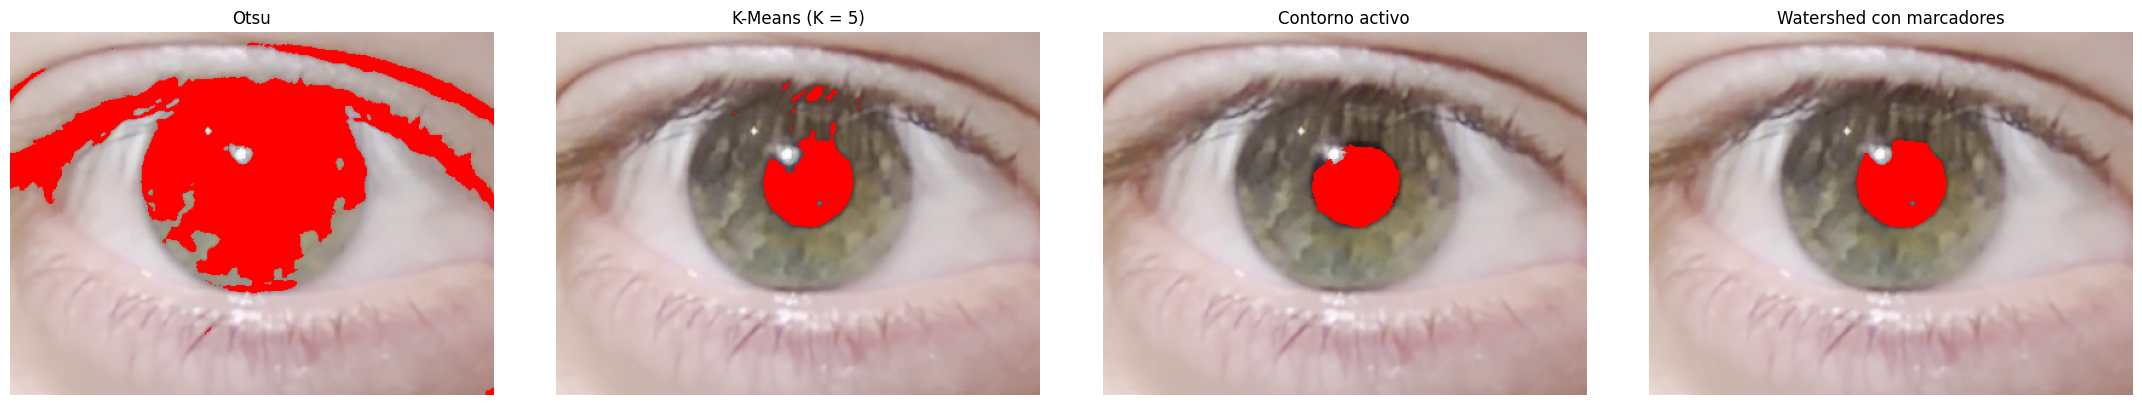

In [ ]:
# Comparación de los cuatro métodos de segmentación
# Usamos las máscaras que ya calculamos en cada sección
mascaras = {
    "Otsu": mascara_otsu,
    "K-Means (K = 5)": mascaras_kmeans[5],
    "Contorno activo": mascara_snake,
    "Watershed con marcadores": mascara_watershed,
}

fig, axes = plt.subplots(1, 4, figsize=(22, 4))

for ax, (nombre, mascara) in zip(axes, mascaras.items()):
    superpuesta = roi.copy()
    superpuesta[mascara == 255] = [255, 0, 0]
    ax.imshow(superpuesta)
    ax.set_title(nombre)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Conclusión de la sección

Otsu** no logró aislar la pupila: al separar la imagen en solo dos clases, el umbral quedó dominado por las regiones de mayor tamaño e incluyó el iris, las pestañas y el párpado. **K-Means** mejoró al aumentar el número de clases, y con K = 5 la clase más oscura correspondió principalmente a la pupila, aunque con fragmentos del iris adheridos y huecos por los reflejos. Los **contornos activos** obtuvieron una pupila compacta, pero requirieron un contorno inicial definido manualmente y resultaron muy sensibles a su posición. **Watershed con marcadores** produjo la segmentación más limpia: una pupila compacta y circular, sin fragmentos del iris, con los reflejos corneales identificados como regiones separadas y sin necesidad de inicialización manual.

Por lo tanto, se elige **watershed con marcadores** como método de segmentación, y su máscara se utiliza en la sección de morfología matemática.